# 01b · Análisis exploratorio de la calidad visual

## Motivación / Objetivos

No todas las cámaras sirven para la investigación: algunas pueden estar desenfocadas, sobreexpuestas o tener poca resolución. Antes de fijar los filtros del preprocesamiento hay que conocer cómo se distribuye la calidad.

Objetivos:
- Medir la resolución, el brillo y la nitidez de las imágenes.
- Separar el análisis por **iluminación** (día / crepúsculo / noche, según la elevación solar): una imagen nocturna oscura no indica una cámara defectuosa.
- Fijar los criterios y umbrales que aplica `02a_preproceso_calidad_contexto`.

**Objetivos del TFM relacionados:** OE-7 (el estado de las cámaras y la iluminación son circunstancias adversas a evaluar).

## Método

Los criterios y umbrales están en `config.yaml` (`calidad`) y el código en `src/calidad.py`, compartido con `02a`.

1. Configuración.
2. Carga de imágenes y cálculo de métricas.
3. Propiedades de las imágenes.
4. Cámaras candidatas a lista negra.

### 1. Configuración

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

PROJECT_ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(PROJECT_ROOT / "src"))

from calidad import add_quality, camera_blacklist, image_metrics, list_camera_images
from config import load_config, path
from tiempo import illumination, parse_timestamp_from_name

CFG = load_config()
RAW_DIR = path("raw")
print(f"Directorio de imágenes: {RAW_DIR}")

Directorio de imágenes: C:\Users\loren\OneDrive\Escritorio\MASTER-UIMP\TFM\tfm\data\malaga\raw


### 2. Carga de imágenes y cálculo de métricas

Se localizan las imágenes de `raw/<cámara>/` (se ignoran las carpetas que no son cámaras, como `.ipynb_checkpoints`) y se calculan las métricas visuales. Para un análisis rápido se limita el número de imágenes por cámara (`MAX_POR_CAMARA`).

In [2]:
MAX_POR_CAMARA = 200  # None = todas (más lento)

image_files = list_camera_images(RAW_DIR)
if MAX_POR_CAMARA is not None:
    by_camera = pd.Series(image_files).groupby([p.parent.name for p in image_files])
    image_files = [p for _, group in by_camera for p in group.sample(min(len(group), MAX_POR_CAMARA), random_state=42)]
print("Imágenes a analizar:", len(image_files))

lat, lon = CFG["ubicacion"]["lat"], CFG["ubicacion"]["lon"]
results = []
for img_path in image_files:
    try:
        metrics = image_metrics(img_path)
    except ValueError:
        continue
    ts = parse_timestamp_from_name(img_path.name)
    metrics["illumination"] = illumination(ts, lat, lon, CFG["iluminacion"]["elevacion_crepusculo"])
    results.append(metrics)

eda_visual = pd.DataFrame(results)
if eda_visual.empty:
    print("No hay imágenes válidas para analizar.")
else:
    display(eda_visual.head())
    print(eda_visual["illumination"].value_counts())

Imágenes a analizar: 5041


,camera,image,width,height,brightness,sharpness,illumination
0,21536,20261012T230457Z.jpg,640,480,83.618128,2324.126888,noche
1,21537,20261012T230608Z.jpg,640,480,84.130059,1805.517781,noche
2,21538,20261012T230623Z.jpg,640,480,78.956016,2398.202407,noche
3,21539,20261012T230624Z.jpg,640,480,64.103757,2292.118519,noche
4,21541,20260826T074150Z.jpg,640,480,94.974759,3051.710793,dia


illumination
dia           4456
noche          551
crepusculo      34
Name: count, dtype: int64


### 3. Propiedades de las imágenes

Resolución, brillo por iluminación y nitidez (en escala logarítmica, por su gran dispersión). El `quality_score` combina los **percentiles** de brillo y nitidez (misma escala 0–1), no sus valores brutos, cuyas escalas difieren en un orden de magnitud.

Resolución:
width  height
640    480       5034
704    576          5
1920   1080         2
Name: count, dtype: int64


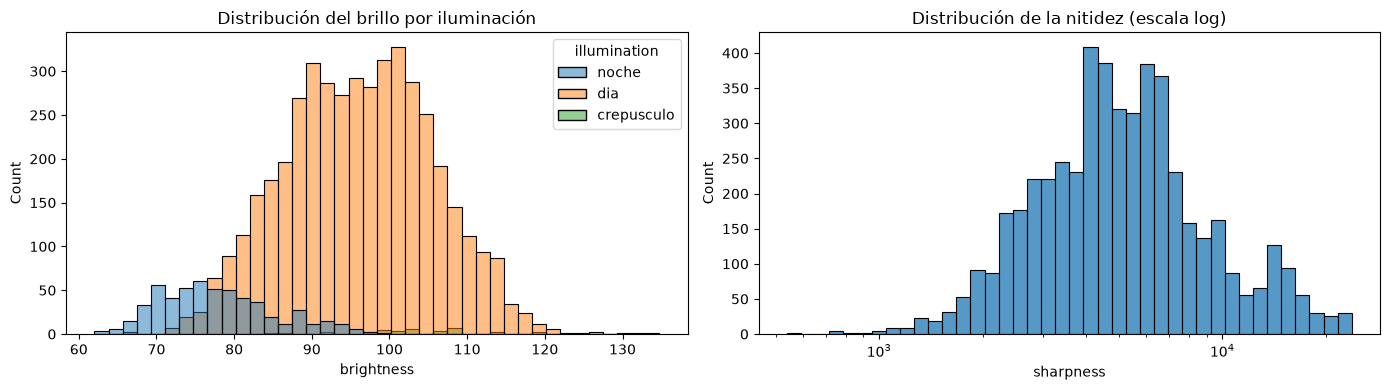

Umbrales aplicados: {'sharpness_min': 2055.8414601300456, 'brightness_min_dia': 30, 'brightness_max': 220}
Imágenes válidas: 95.0%
Cámaras más oscuras de día:
camera
75099    73.481180
21585    73.806367
21611    75.208906
75071    76.543955
21542    77.685544
75074    78.365049
75076    78.451149
21589    80.344434
21558    81.321992
75069    82.167726
Name: brightness, dtype: float64
Cámaras más borrosas:
camera
21537    1805.517781
21607    2064.322694
21620    2277.250398
21539    2292.118519
21536    2324.126888
21589    2350.263095
21538    2398.202407
21611    2435.800431
21613    2598.653344
75076    2772.386935
Name: sharpness, dtype: float64
Mejores cámaras por score de utilidad:
camera
21598    0.836333
21616    0.821770
21580    0.777080
21599    0.651696
21568    0.640827
21567    0.639704
21553    0.630983
75072    0.609826
21595    0.608022
21579    0.605607
Name: quality_score, dtype: float64


In [3]:
if not eda_visual.empty:
    print("Resolución:")
    print(eda_visual[["width", "height"]].value_counts().head(10))

    fig, axes = plt.subplots(1, 2, figsize=(14, 4))
    sns.histplot(data=eda_visual, x="brightness", hue="illumination", bins=40, ax=axes[0])
    axes[0].set_title("Distribución del brillo por iluminación")
    sns.histplot(data=eda_visual, x="sharpness", bins=40, log_scale=True, ax=axes[1])
    axes[1].set_title("Distribución de la nitidez (escala log)")
    plt.tight_layout()
    plt.show()

    eda_visual, thresholds = add_quality(eda_visual, CFG["calidad"])
    print("Umbrales aplicados:", thresholds)
    print(f"Imágenes válidas: {eda_visual['valid'].mean():.1%}")

    print("Cámaras más oscuras de día:")
    print(eda_visual[eda_visual["illumination"] == "dia"].groupby("camera")["brightness"].mean().nsmallest(10))

    print("Cámaras más borrosas:")
    print(eda_visual.groupby("camera")["sharpness"].median().nsmallest(10))

    print("Mejores cámaras por score de utilidad:")
    print(eda_visual.groupby("camera")["quality_score"].mean().nlargest(10))
else:
    print("No hay datos suficientes para construir gráficos de calidad visual.")

### 4. Cámaras candidatas a lista negra

Una cámara se descarta solo si falla más del `max_fraccion_fallos` de sus imágenes **de día**. La lista definitiva la guarda `02a`.

In [4]:
if not eda_visual.empty:
    stats = camera_blacklist(eda_visual, CFG["calidad"]["max_fraccion_fallos"])
    display(stats.sort_values("fraccion_fallos", ascending=False).head(15))
    print(f"Cámaras en lista negra: {stats['en_lista_negra'].sum()} de {len(stats)}")

,camera,n_imagenes,fraccion_fallos,en_lista_negra
3,21545,179,0.234637,False
0,21541,181,0.127072,False
5,21547,182,0.060440,False
12,21554,182,0.060440,False
22,21564,179,0.050279,False
45,21587,181,0.049724,False
40,21582,178,0.039326,False
128,78681,179,0.027933,False
61,21603,178,0.011236,False
53,21595,179,0.011173,False


Cámaras en lista negra: 0 de 129


## Salida / Resultados

No genera ficheros: la lista negra definitiva la escribe `02a`.

**Última ejecución** (muestra de hasta 200 imágenes por cámara, 5.041 imágenes):
- Iluminación: 4.456 de día, 551 de noche y 34 de crepúsculo.
- Resolución: 640×480 en 5.034 imágenes; 5 a 704×576 y 2 a 1920×1080.
- Umbral de nitidez (percentil 5): 2.056. Imágenes válidas: 95,0 %.
- Cámaras en lista negra: 0 de 129. La que más falla, la 21545, falla el 23,5 % de sus imágenes de día.

## Observaciones

- Esta muestra es anterior a buena parte de la captura. `02a`, con las 78.957 imágenes, obtiene un umbral de nitidez de 1.838 y un 8,3 % de fallos en la 21545.
- La introducción original prometía comprobar si cada cámara permite ver peatones, vehículos y semáforos. Eso no se mide aquí, sino con los conteos de `02c_preproceso_deteccion_yolo26`.
- La resolución apenas varía: YOLO redimensiona a 640 px, así que las 7 imágenes de otra resolución no necesitan un tratamiento aparte.